In [1]:
# 1. Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Load the synthetic dataset
DATA_PATH = "../data/synthetic_pain_patients.csv"
df = pd.read_csv(DATA_PATH)

# 3. First look
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (2000, 20)


,patient_id,mechanism,pain_duration_months,pain_distribution,dn4_score,paindetect_score,csi_score,sleep_quality,imaging_tissue_finding,imaging_nerve_compression,hads_anxiety,hads_depression,pcs_score,tsk_score,work_stress,rf_cancer_history,rf_systemic_signs,rf_cauda_equina,rf_inflammatory,any_red_flag
0,1,mixed,36.9,widespread,3.0,18.0,55.0,4,not_performed,not_performed,9.0,11.0,NaN,36.0,5,False,False,False,False,False
1,2,neuropathic,13.6,dermatomal,5.0,20.0,43.0,2,not_performed,not_performed,7.0,7.0,4.0,32.0,4,False,False,False,False,False
2,3,mixed,9.1,dermatomal,2.0,17.0,48.0,4,no,no,8.0,5.0,25.0,40.0,2,False,False,False,False,False
3,4,nociplastic,65.0,widespread,1.0,16.0,56.0,4,not_performed,not_performed,12.0,NaN,17.0,40.0,9,False,False,False,False,False
4,5,nociceptive,0.8,localized,2.0,4.0,24.0,4,yes,no,6.0,8.0,13.0,43.0,5,False,False,False,False,False


In [2]:
# Column names, non-missing counts and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 20 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   patient_id                 2000 non-null   int64  
 1   mechanism                  2000 non-null   str    
 2   pain_duration_months       2000 non-null   float64
 3   pain_distribution          2000 non-null   str    
 4   dn4_score                  1940 non-null   float64
 5   paindetect_score           1918 non-null   float64
 6   csi_score                  1728 non-null   float64
 7   sleep_quality              2000 non-null   int64  
 8   imaging_tissue_finding     2000 non-null   str    
 9   imaging_nerve_compression  2000 non-null   str    
 10  hads_anxiety               1915 non-null   float64
 11  hads_depression            1841 non-null   float64
 12  pcs_score                  1913 non-null   float64
 13  tsk_score                  1917 non-null   float64
 14  wor

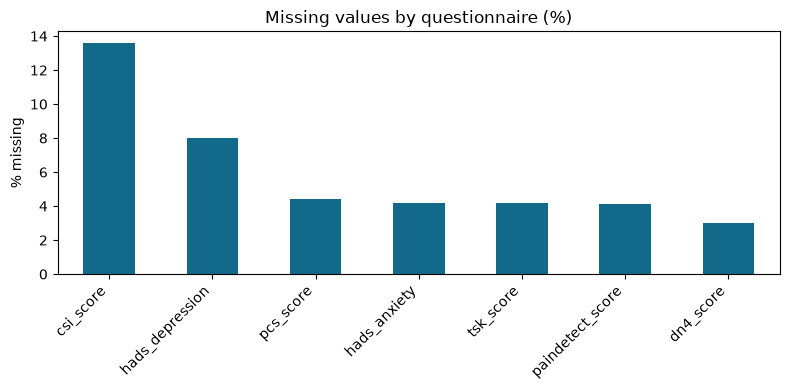

In [3]:
# % missing per column (only columns with missing values)
missing_pct = df.isna().mean().mul(100).round(1)
missing_pct = missing_pct[missing_pct > 0].sort_values(ascending=False)

# Bar chart
fig, ax = plt.subplots(figsize=(8, 4))
missing_pct.plot(kind="bar", ax=ax, color="#13698A")
ax.set_title("Missing values by questionnaire (%)")
ax.set_ylabel("% missing")
ax.set_xlabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [4]:
# % missing by mechanism: is missingness related to the class?
missing_cols = missing_pct.index.tolist()

(
    df[missing_cols]
    .isna()
    .groupby(df["mechanism"])
    .mean()
    .mul(100)
    .round(1)
)

,csi_score,hads_depression,pcs_score,hads_anxiety,tsk_score,paindetect_score,dn4_score
mechanism,,,,,,,
mixed,5.7,8.6,4.0,3.4,4.8,3.4,2.9
neuropathic,6.9,8.5,2.0,3.9,3.6,4.3,3.6
nociceptive,26.6,5.7,5.1,4.4,4.4,3.9,2.8
nociplastic,2.9,11.3,5.2,5.2,3.1,5.2,3.1


In [5]:
# Numeric clinical and questionnaire variables
numeric_cols = [
    "pain_duration_months", "dn4_score", "paindetect_score", "csi_score",
    "sleep_quality", "hads_anxiety", "hads_depression", "pcs_score",
    "tsk_score", "work_stress",
]

# Summary statistics (one row per variable)
df[numeric_cols].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
pain_duration_months,2000.0,12.7,17.4,0.2,2.4,6.5,16.4,208.5
dn4_score,1940.0,3.0,2.0,0.0,1.0,3.0,4.0,10.0
paindetect_score,1918.0,13.6,7.1,-1.0,8.0,13.0,19.0,38.0
csi_score,1728.0,37.2,16.2,0.0,25.0,36.0,48.0,96.0
sleep_quality,2000.0,5.5,1.9,0.0,4.0,5.0,7.0,10.0
hads_anxiety,1915.0,7.4,3.6,0.0,5.0,7.0,10.0,17.0
hads_depression,1841.0,6.2,3.5,0.0,4.0,6.0,8.0,20.0
pcs_score,1913.0,19.2,10.0,0.0,12.0,19.0,26.0,52.0
tsk_score,1917.0,38.4,7.2,17.0,34.0,38.0,43.0,68.0
work_stress,2000.0,5.1,2.1,0.0,4.0,5.0,7.0,10.0


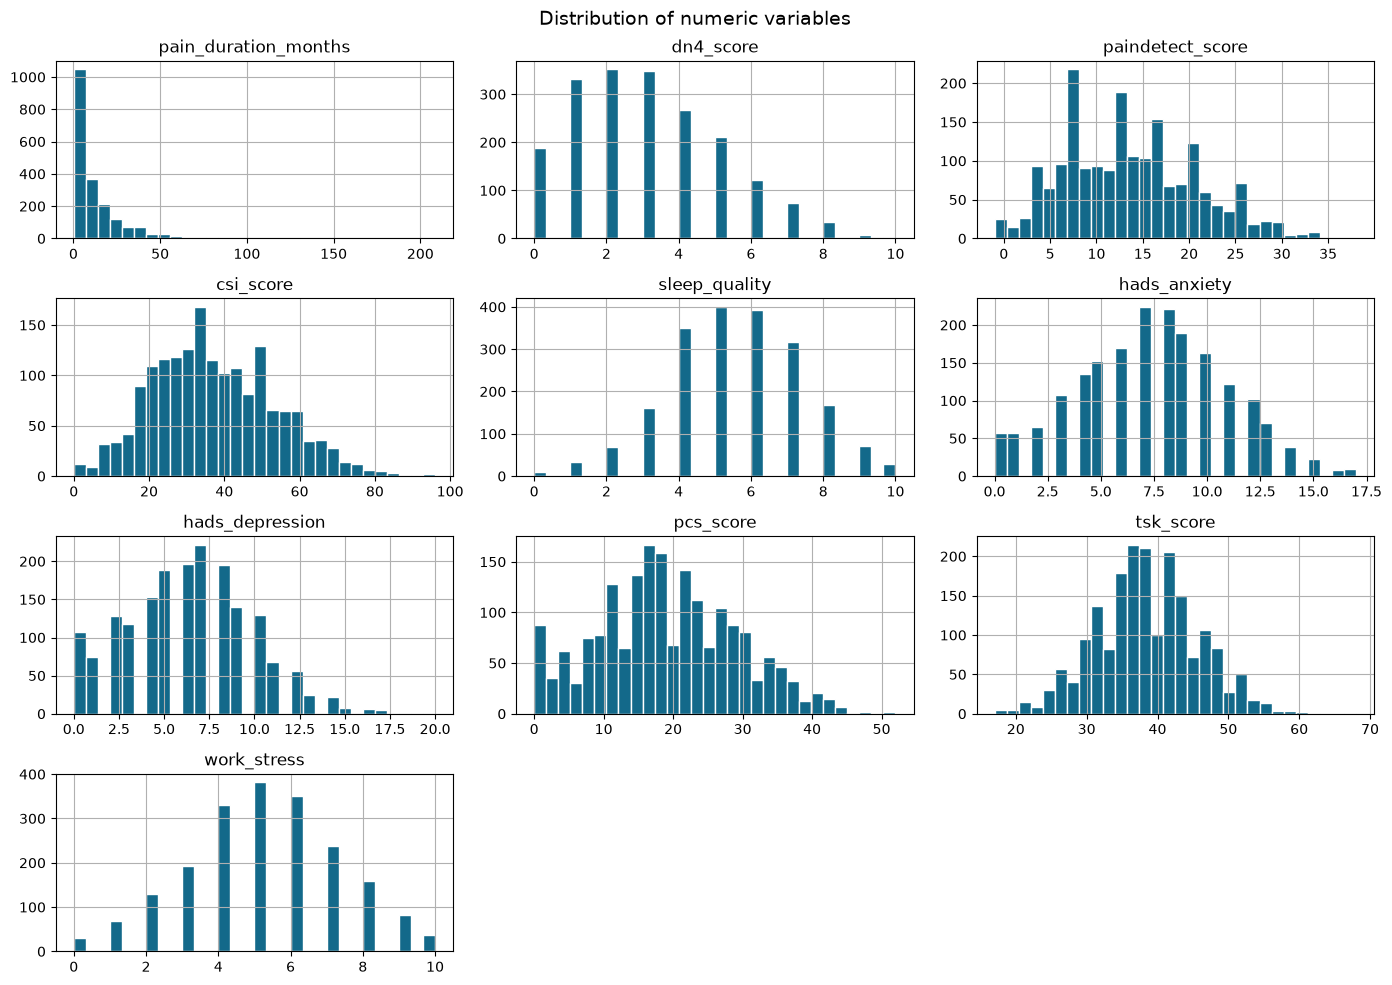

In [6]:
# Histograms: the shape of each distribution
df[numeric_cols].hist(bins=30, figsize=(14, 10), color="#13698A", edgecolor="white")
plt.suptitle("Distribution of numeric variables", fontsize=14)
plt.tight_layout()
plt.show()

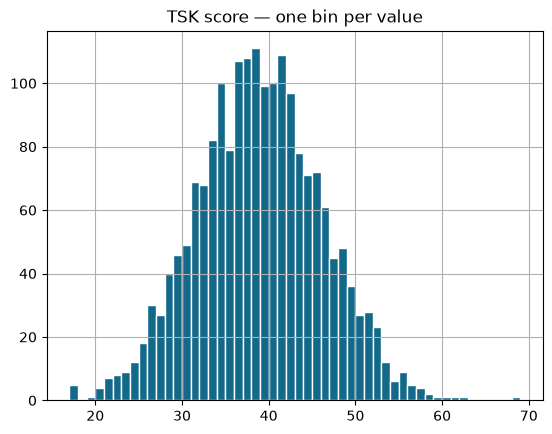

In [7]:
# TSK histogram with one bin per whole number (no binning artifact)
bins = range(17, 70)
df["tsk_score"].hist(bins=bins, color="#13698A", edgecolor="white")
plt.title("TSK score — one bin per value")
plt.show()